# Landau-Lifshitz-Bloch Dynamics

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/dschick/udkm1Dsim/blob/develop/examples/04-magnetization/03-LLB.ipynb)

In the [LLG](#example_LLG) the amplitude of the magnetization is an input.
The Landau-Lifshitz-Bloch (LLB) equation describes its dynamics together with the one of its direction, which is required e.g. for the strong demagnetization close to and above the Curie temperature.
The {py:class}`LLB <udkm1Dsim.simulations.magnetization.LLB>` solves the mean-field LLB for the magnetization $\mathbf{m}$ of every layer

\begin{align*}
\frac{d\mathbf{m}}{dt} = \gamma \left(\mathbf{m} \times \mathbf{B}
+ \frac{\alpha_{\perp}}{m^2}\mathbf{m} \times (\mathbf{m} \times \mathbf{B})
- \frac{\alpha_{\parallel}}{m^2}(\mathbf{m} \cdot \mathbf{B}) \mathbf{m}\right)
\end{align*}

with the gyromagnetic ratio $\gamma$, the precession, the transverse, and the longitudinal relaxation.
The longitudinal field in $\mathbf{B}$ relaxes the amplitude towards the mean-field equilibrium $m_\mathrm{eq}(T)$ of the temperature with the longitudinal susceptibility $\chi_\parallel(T)$.
The damping parameters $\alpha_\parallel(T)$ and $\alpha_\perp(T)$ follow from the coupling to the bath $\lambda$ (`lamda`), the effective spin $S$ (`eff_spin`), and the Curie temperature $T_C$.
Finite spins give the quantum LLB {cite:p}`nieves2014`, an infinite spin the classical one {cite:p}`atxitia2017`.

Several sublattices, e.g. of ferri- and antiferromagnets, are coupled by the mean-field exchange matrix of the layer {cite:p}`atxitia2012,raposo2022`, which is demonstrated for a simple antiferromagnet at the end.

:::{admonition} References {cite}`atxitia2017,nieves2014,atxitia2012,raposo2022`
:class: seealso
U. Atxitia, D. Hinzke, and U. Nowak,
*Fundamentals and applications of the Landau-Lifshitz-Bloch equation*,
[J. Phys. D: Appl. Phys. 50, 033003 (2017)](https://doi.org/10.1088/1361-6463/50/3/033003)

P. Nieves, D. Serantes, U. Atxitia, and O. Chubykalo-Fesenko,
*Quantum Landau-Lifshitz-Bloch equation and its comparison with the classical case*,
[Phys. Rev. B 90, 104428 (2014)](https://doi.org/10.1103/PhysRevB.90.104428)
:::

## Setup

Do all necessary imports and settings.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

try:
    import udkm1Dsim as ud
except ImportError:
    %pip install udkm1Dsim
    import udkm1Dsim as ud

from udkm1Dsim.simulations.solvers import mean_field

u = ud.u  # import the pint unit registry from udkm1Dsim
u.setup_matplotlib()  # use matplotlib with pint units

%matplotlib inline

/home/schick/Programming/git/udkm1Dsim-review/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Structure

Refer to the [structure example](#example_structure) for more details.

The sample is a 10 nm thick Ni film on top of a 5 nm thick Fe film on 100 nm of Si, which is continued by a semi-infinite Si substrate for the optical absorption.
Every 1 nm thick layer is a macrospin.
Besides the parameters of the [LLG](#example_LLG), solving the LLB requires the following parameters of the {py:class}`magnetic <udkm1Dsim.structures.parameter_groups.MagneticParameters>` parameter group of the according {py:class}`Layer <udkm1Dsim.structures.layers.Layer>` objects:

* `eff_spin` $S$ - effective spin
* `curie_temp` $T_\mathrm{C}$ - Curie temperature
* `lamda` $\lambda$ - coupling to the bath used in the longitudinal & transversal damping terms $\alpha_\parallel$ & $\alpha_\perp$ (misspelled because of python `lambda`-functions)
* `mag_moment` $\mu$ - atomic magnetic moment, here derived from the saturation magnetization and the number density $n$ of the atoms as $\mu = M_s / n$

Magnetic layers of the LLB are those with a Curie temperature.
The anisotropy requires an `aniso_exponent` of at least 2, since the anisotropy field scales with $m_\mathrm{eq}^{\beta-2}$.

In [2]:
# Ni parameters for the two-temperature model and the LLB
rho = 8900 * u.kg / u.m**3  # density
g = 8e17 * u.W / (u.m**3 * u.K)  # electron-phonon coupling
M_s = 4.9e5 * u.A / u.m  # saturation magnetization
K_shape = (u.mu_0 * M_s**2 / 2).to("J/m**3")  # shape anisotropy
# atomic magnetic moment from the number density of the Ni atoms
mu = (M_s / (rho / (58.69 * u.g / u.mol) * u.N_A)).to("bohr_magneton")

layer_Ni = ud.Layer(
    "Ni",
    "Nickel",
    structural=ud.StructuralParameters(thickness=1 * u.nm, density=rho),
    # two-temperature model of the electrons and phonons
    thermal=ud.ThermalParameters(
        heat_capacity=["0.12*T", 444 * u.J / (u.kg * u.K)],
        therm_cond=[90 * u.W / (u.m * u.K), 5 * u.W / (u.m * u.K)],
        sub_system_coupling=[
            f"-{g.m_as('W/(m**3*K)'):g}*(T_0-T_1)",
            f"{g.m_as('W/(m**3*K)'):g}*(T_0-T_1)",
        ],
        lin_therm_exp=[0, 13.4e-6 / u.K],
        sub_system_labels=["e", "p"],
    ),
    elastic=ud.ElasticParameters(sound_vel=5.58 * u.nm / u.ps),
    optical=ud.OpticalParameters(dielectric=ud.Dispersion.from_ref_index(2.9174 + 3.3545j)),
    # LLB parameters
    magnetic=ud.MagneticParameters(
        mag_saturation=M_s,
        gilbert_damping=0.03,
        # in-plane easy axis along x and shape anisotropy
        anisotropy=[5e3, 0, 0] * u.J / u.m**3 + [0, 0, -1] * K_shape,
        aniso_exponent=2,
        exch_stiffness=1e-11 * u.J / u.m,
        magnetoelastic_coupling=6.2e6 * u.J / u.m**3,
        eff_spin=0.5,
        curie_temp=630 * u.K,
        mag_moment=mu,
        lamda=0.1,
        magnetization=(1, 0, 0),
    ),
)

In [3]:
# Fe layer
rho = 7874 * u.kg / u.m**3
g = 7e17 * u.W / (u.m**3 * u.K)
M_s = 1.71e6 * u.A / u.m
K_shape = (u.mu_0 * M_s**2 / 2).to("J/m**3")
mu = (M_s / (rho / (55.845 * u.g / u.mol) * u.N_A)).to("bohr_magneton")

layer_Fe = ud.Layer(
    "Fe",
    "Iron",
    structural=ud.StructuralParameters(thickness=1 * u.nm, density=rho),
    thermal=ud.ThermalParameters(
        heat_capacity=["0.085*T", 450 * u.J / (u.kg * u.K)],
        therm_cond=[80 * u.W / (u.m * u.K), 5 * u.W / (u.m * u.K)],
        sub_system_coupling=[
            f"-{g.m_as('W/(m**3*K)'):g}*(T_0-T_1)",
            f"{g.m_as('W/(m**3*K)'):g}*(T_0-T_1)",
        ],
        lin_therm_exp=[0, 11.8e-6 / u.K],
        sub_system_labels=["e", "p"],
    ),
    elastic=ud.ElasticParameters(sound_vel=5.9 * u.nm / u.ps),
    optical=ud.OpticalParameters(dielectric=ud.Dispersion.from_ref_index(2.8954 + 2.9179j)),
    magnetic=ud.MagneticParameters(
        mag_saturation=M_s,
        gilbert_damping=0.005,
        anisotropy=[4.8e4, 0, 0] * u.J / u.m**3 + [0, 0, -1] * K_shape,
        aniso_exponent=2,
        exch_stiffness=2e-11 * u.J / u.m,
        magnetoelastic_coupling=-3.4e6 * u.J / u.m**3,
        eff_spin=2,
        curie_temp=1044 * u.K,
        mag_moment=mu,
        lamda=0.02,
        magnetization=(1, 0, 0),
    ),
)

In [4]:
# Si is not magnetic
layer_Si = ud.Layer(
    "Si",
    "Silicon",
    structural=ud.StructuralParameters(thickness=1 * u.nm, density=2336 * u.kg / u.m**3),
    thermal=ud.ThermalParameters(
        heat_capacity=[100 * u.J / (u.kg * u.K), 603 * u.J / (u.kg * u.K)],
        therm_cond=[0, 100 * u.W / (u.m * u.K)],
        sub_system_coupling=[0, 0],
        lin_therm_exp=[0, 2.6e-6 / u.K],
        sub_system_labels=["e", "p"],
    ),
    elastic=ud.ElasticParameters(sound_vel=8.433 * u.nm / u.ps),
    optical=ud.OpticalParameters(dielectric=ud.Dispersion.from_ref_index(3.6941 + 0.0065435j)),
)

In [5]:
S = ud.Structure("Ni/Fe on Si")
S.add_sub_structure(layer_Ni, 10)
S.add_sub_structure(layer_Fe, 5)
S.add_sub_structure(layer_Si, 100)
# add a semi-infinite, static Si substrate for the optical absorption
S.add_substrate(layer_Si)

_, _, distances = S.get_distances_of_layers()
select_Ni = S.get_all_positions_per_unique_layer()["Ni"]
select_Fe = S.get_all_positions_per_unique_layer()["Fe"]
layer_Ni.magnetic

Parameter,Symbol,Value,Unit
eff_spin,S,0.5,
curie_temp,TC,630,K
mf_exch_coupling,J,8.698×10−21,kg m2/s2
lamda,λ,0.1,
mag_moment,μ,5.366×10−24,A m2
aniso_exponent,β,2,
anisotropy,K,"[5000, 0, −1.509×105]",J/m3
exch_stiffness,Aex,"[1×10−11, 1×10−11, 1×10−11]",J/m
mag_saturation,Ms,4.9×105,J/(m3 T)
magnetization,r,1,


## Landau-Lifshitz-Bloch Simulations

The {py:class}`LLB <udkm1Dsim.simulations.magnetization.LLB>` class requires a {py:class}`Structure <udkm1Dsim.structures.structure.Structure>` object and a boolean `force_recalc` in order to overwrite previous simulation results.

These results are saved in the `cache_dir` when `save_data` is enabled.
Printing simulation messages can be en-/disabled using `disp_messages` and progress bars can be enabled using the boolean switch `progress_bar`.
Refer to the [LLG example](#example_LLG) for more details on the `ode_options`.

## Mean-Field Magnetization

The equilibrium amplitude $m_\mathrm{eq}(T)$ is the solution of the self-consistent mean-field equation with the Brillouin function of the effective spin - the Langevin function for an infinite spin - see {py:meth}`get_mean_field_mag_map <udkm1Dsim.simulations.magnetization.Magnetization.get_mean_field_mag_map>`.

In [6]:
llb = ud.LLB(S, True)

llb.save_data = False
llb.disp_messages = False
llb.progress_bar = False
llb.ode_options.update({"rtol": 1e-6, "atol": 1e-9})

llb

Landau-Lifshitz-Bloch Magnetization Dynamics simulation properties:

======================  =======
             parameter  value
======================  =======
          force recalc  True
       cache directory  ./
      display messages  False
             save data  False
          progress bar  False
temperature sub-system  0
======================  =======

This is the current structure for the simulations:

Structure properties:

Name   : Ni/Fe on Si
Thickness : 115 nm
----
10 times Nickel: 10 nm
5 times Iron: 5 nm
100 times Silicon: 100 nm
----
Superstrate (semi-infinite):
----
1 times vacuum: 1 nm
----
Substrate (semi-infinite):
----
1 times Silicon: 1 nm

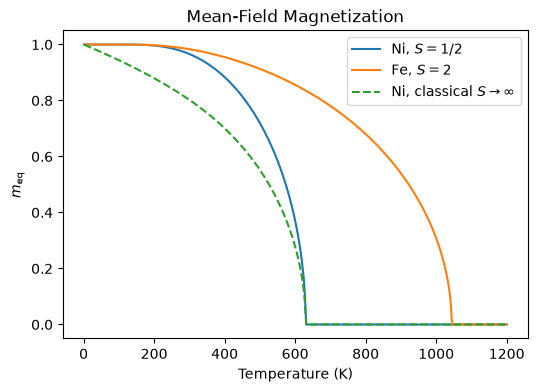

In [7]:
temps = np.linspace(1, 1200, 600)
temp_map = np.tile(temps[:, np.newaxis], (1, S.get_number_of_layers()))
mf_mag_map = llb.get_mean_field_mag_map(temp_map)

plt.figure(figsize=[6, 4])

plt.plot(temps, mf_mag_map[:, select_Ni[0]], label="Ni, $S = 1/2$")
plt.plot(temps, mf_mag_map[:, select_Fe[0]], label="Fe, $S = 2$")
plt.plot(
    temps,
    mean_field.mean_field_magnetization(temps / 630, np.inf),
    "--",
    label="Ni, classical $S \\rightarrow \\infty$",
)
plt.xlabel("Temperature (K)")
plt.ylabel("$m_\\mathrm{eq}$")
plt.title("Mean-Field Magnetization")
plt.legend()
plt.show()

## Laser-Induced Demagnetization

A laser pulse heats the electrons of a two-temperature model, now with two fluences, the larger of which heats the Ni above its Curie temperature.
The LLB starts in the equilibrium of the first delay (`equilibrate=True`), i.e. with the mean-field amplitude of 300 K and the directions relaxed into the external field of 0.5 T at 45°, and its amplitude follows the electron temperature (`temp_sub_system`) with the longitudinal relaxation.

:::{versionchanged} 2.6.1
The magnetization maps are returned in cartesian coordinates $[m_x, m_y, m_z]$ by default, as the `magnetization` of the layers.
Before, they were returned in polar coordinates $[r, \phi, \gamma]$, which are still available by `polar=True`.
:::

In [8]:
B_0 = 0.5 * u.T
B_ext = B_0 * np.array([np.cos(np.radians(45)), 0, np.sin(np.radians(45))])
delays = np.r_[-2:5:0.01, 5:300:0.25] * u.ps

h = ud.Heat(S, True)
h.save_data = False
h.disp_messages = False
h.progress_bar = False
h.heat_diffusion = True
h.boundary_conditions = {"top_type": "isolator", "bottom_type": "isolator"}

fluences = [1, 4]  # mJ/cm^2
results = {}
for fluence in fluences:
    h.excitation = {
        "fluence": [fluence] * u.mJ / u.cm**2,
        "delay_pump": [0] * u.ps,
        "pulse_width": [0.1] * u.ps,
        "multilayer_absorption": True,
        "wavelength": 800 * u.nm,
        "theta": 45 * u.deg,
    }
    temp_map, _ = h.get_temp_map(delays, 300 * u.K)
    print(
        f"{fluence} mJ/cm²: largest electron temperature of the Ni "
        f"{temp_map[:, select_Ni, 0].max():.0f} K"
    )
    results[fluence] = {
        "temp_map": temp_map,
        "llb": llb.get_magnetization_map(delays, temp_map=temp_map, B_ext=B_ext, equilibrate=True),
        "mean_field": llb.get_mean_field_mag_map(temp_map[:, :, 0]),
    }

1 mJ/cm²: largest electron temperature of the Ni 547 K


4 mJ/cm²: largest electron temperature of the Ni 988 K


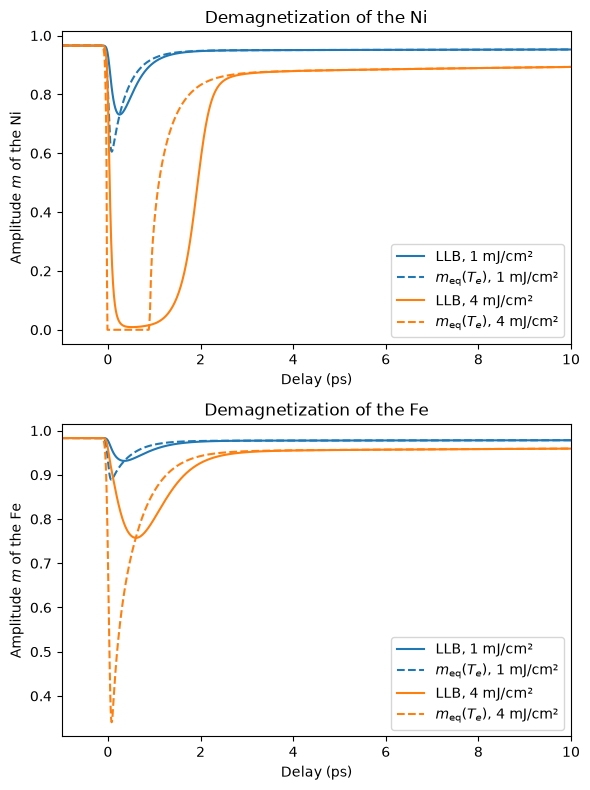

In [9]:
plt.figure(figsize=[6, 8])
for i, (name, select) in enumerate((("Ni", select_Ni), ("Fe", select_Fe))):
    plt.subplot(2, 1, i + 1)
    for k, fluence in enumerate(fluences):
        result = results[fluence]
        plt.plot(
            delays,
            np.mean(np.linalg.norm(result["llb"][:, select], axis=-1), axis=1),
            color=f"C{k}",
            label=f"LLB, {fluence} mJ/cm²",
        )
        plt.plot(
            delays,
            np.mean(result["mean_field"][:, select], axis=1),
            "--",
            color=f"C{k}",
            label=f"$m_\\mathrm{{eq}}(T_e)$, {fluence} mJ/cm²",
        )
    plt.xlim(-1, 10)
    plt.xlabel("Delay (ps)")
    plt.ylabel(f"Amplitude $m$ of the {name}")
    plt.title(f"Demagnetization of the {name}")
    plt.legend()
plt.tight_layout()
plt.show()

The amplitude of the LLB lags behind the mean field of the electron temperature, as the longitudinal relaxation needs time, which grows towards the Curie temperature (critical slowing down).
At the larger fluence the Ni is quenched strongly, as its electrons exceed the Curie temperature, and recovers only slowly, whereas the Fe with its much higher Curie temperature is only weakly demagnetized.

## Comparison with the LLG

The [LLG](#example_LLG) with the mean-field amplitude of the electron temperature is the adiabatic limit of the LLB, in which the amplitude follows the temperature instantaneously.
For a fair comparison of the precession, the Gilbert damping of the LLG is set to the transverse damping of the LLB at 300 K, $\alpha = \alpha_\perp/m_\mathrm{eq}$ with $\alpha_\perp = \lambda\left(\frac{\tanh q}{q} - \frac{T}{3T_C}\right)$ and $q = \frac{3T_C m_\mathrm{eq}}{2(S+1)T}$ {cite:p}`nieves2014`.

Ni: Gilbert damping 0.0329
Fe: Gilbert damping 0.0092


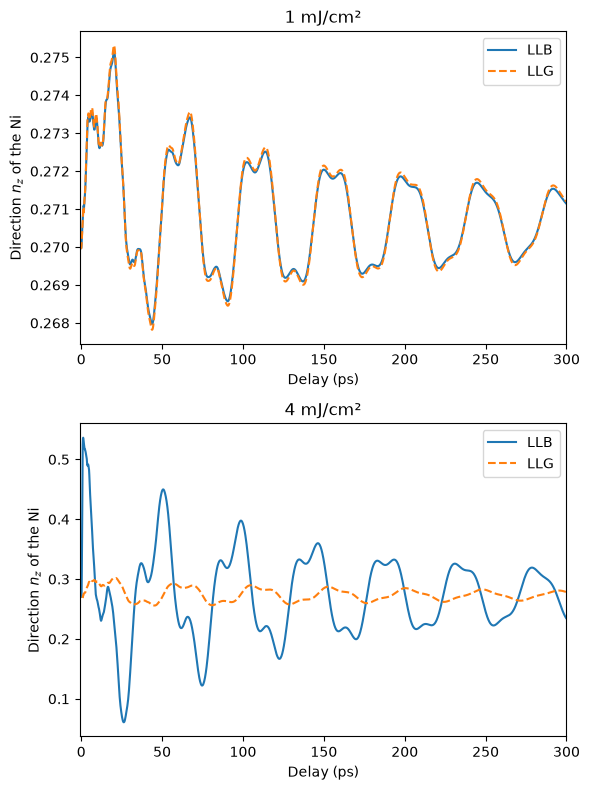

In [10]:
for layer in (layer_Ni, layer_Fe):
    S_eff, T_C, lam = layer.eff_spin.magnitude, layer.curie_temp.magnitude, layer.lamda.magnitude
    m_eq = mean_field.mean_field_magnetization(300 / T_C, S_eff)
    q = 3 * T_C * m_eq / (2 * (S_eff + 1) * 300)
    layer.gilbert_damping = lam * (np.tanh(q) / q - 300 / (3 * T_C)) / m_eq
    print(f"{layer.id}: Gilbert damping {layer.gilbert_damping.magnitude:.4f}")

llg = ud.LLG(S, True)

llg.save_data = False

llg.disp_messages = False

llg.progress_bar = False
llg.ode_options.update({"rtol": 1e-6, "atol": 1e-9})
for fluence in fluences:
    results[fluence]["llg"] = llg.get_magnetization_map(
        delays, temp_map=results[fluence]["temp_map"], B_ext=B_ext, equilibrate=True
    )

plt.figure(figsize=[6, 8])
for i, fluence in enumerate(fluences):
    plt.subplot(2, 1, i + 1)
    for label, style in (("llb", "-"), ("llg", "--")):
        result = results[fluence][label]
        # direction n_z = m_z / m, which is undefined for a vanishing
        # amplitude above the Curie temperature
        m = np.linalg.norm(result[:, select_Ni], axis=-1)
        n_z = np.divide(result[:, select_Ni, 2], m, out=np.full_like(m, np.nan), where=m > 0)
        plt.plot(delays, np.mean(n_z, axis=1), style, label=label.upper())
    plt.xlim(-1, 300)
    plt.xlabel("Delay (ps)")
    plt.ylabel("Direction $n_z$ of the Ni")
    plt.title(f"{fluence} mJ/cm²")
    plt.legend()
plt.tight_layout()
plt.show()

At the small fluence the LLB and the LLG agree well.
At the large fluence, the amplitude of the LLG vanishes as long as the electrons of the Ni are above its Curie temperature, where its direction is undefined, and returns instantaneously as they cool below it.
The amplitude of the LLB is quenched for longer and recovers with its longitudinal relaxation, which keeps the anisotropy field reduced for longer and drives a much larger precession - close to and above the Curie temperature, the adiabatic limit of the LLG fails.

## A Simple Antiferromagnet

A layer with several sublattices is described by per-sublattice parameters, which are given as one value per sublattice or as a scalar for all of them, by one magnetization per sublattice, and by the mean-field exchange matrix $J_{ab}$ `mf_exch_coupling`, see {py:class}`MagneticParameters <udkm1Dsim.structures.parameter_groups.MagneticParameters>`.
Its row $a$ holds the couplings of the field on sublattice $a$, negative off-diagonal elements couple antiferromagnetically.
The Curie (here Néel) temperature is then derived from the matrix as the ordering temperature of the coupled sublattices.

Two identical sublattices with $S = 1/2$ are taken, with a ferromagnetic coupling $J_1$ within and an antiferromagnetic one $-J_2$ between them, which order at $T_N = \frac{S+1}{3S}\frac{J_1 + J_2}{k_B}$.

In [11]:
# exchange couplings J_1 and -J_2 as energies k_B T,
# i.e. 3S/(S+1) = 1 times k_B times 300 K and 250 K
J = [[300, -250], [-250, 300]] * u.K * u.k_B
layer_AFM = ud.Layer(
    "AFM",
    "antiferromagnet",
    structural=ud.StructuralParameters(thickness=1 * u.nm, density=7000 * u.kg / u.m**3),
    magnetic=ud.MagneticParameters(
        eff_spin=0.5,  # for both sublattices
        lamda=0.05,
        mag_moment=1 * u.bohr_magneton,
        mag_saturation=[5e5, 5e5] * u.A / u.m,
        mf_exch_coupling=J,
        # one magnetization per sublattice, antiparallel along z
        magnetization=[(0, 0, 1), (0, 0, -1)],
    ),
)
S_AFM = ud.Structure("AFM")
S_AFM.add_sub_structure(layer_AFM, 5)

print(f"number of sublattices: {layer_AFM.num_sublattices}")
print(
    f"Néel temperature: {layer_AFM.curie_temp.to('K'):.1f~P}, "
    f"expected {((J[0, 0] - J[0, 1]) / u.k_B).to('K'):.1f~P}"
)
layer_AFM.magnetic

number of sublattices: 2
Néel temperature: 550.0 K, expected 550.0 K


Parameter,Symbol,Value,Unit
eff_spin,S,0.5,
curie_temp,TC,550,K
mf_exch_coupling,J,"[[4.142×10−21, −3.452×10−21], [−3.452×10−21, 4.142×10−21]]",kg m2/s2
lamda,λ,0.05,
mag_moment,μ,9.274×10−24,A m2
aniso_exponent,β,0,
anisotropy,K,"[0, 0, 0]",J/m3
exch_stiffness,Aex,"[0, 0, 0]",J/m
mag_saturation,Ms,"[5×105, 5×105]",J/(m3 T)
magnetization_1,r,1,


The sublattices have the same mean-field magnetization, see {py:meth}`get_sublattice_mean_field_mag_map <udkm1Dsim.simulations.magnetization.Magnetization.get_sublattice_mean_field_mag_map>`, whereas the net magnetization of the layer, i.e. the sum of the sublattice magnetizations weighted by their saturation magnetizations, vanishes.

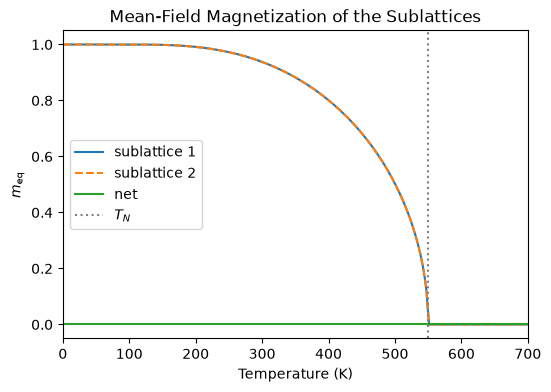

In [12]:
llb_AFM = ud.LLB(S_AFM, True)
llb_AFM.save_data = False
llb_AFM.disp_messages = False
llb_AFM.progress_bar = False
temp_map = np.tile(temps[:, np.newaxis], (1, 5))
sublattice_mf = llb_AFM.get_sublattice_mean_field_mag_map(temp_map)
net_mf = llb_AFM.get_mean_field_mag_map(temp_map)

plt.figure(figsize=[6, 4])
plt.plot(temps, sublattice_mf[:, 0, 0], label="sublattice 1")
plt.plot(temps, sublattice_mf[:, 0, 1], "--", label="sublattice 2")
plt.plot(temps, net_mf[:, 0], label="net")
plt.axvline(layer_AFM.curie_temp.magnitude, color="gray", ls=":", label="$T_N$")
plt.xlim(0, 700)
plt.xlabel("Temperature (K)")
plt.ylabel("$m_\\mathrm{eq}$")
plt.title("Mean-Field Magnetization of the Sublattices")
plt.legend()
plt.show()

The antiferromagnet is heated by a temperature pulse, which is given directly as `temp_map`, and the magnetization of both sublattices is returned by {py:meth}`get_sublattice_magnetization_map <udkm1Dsim.simulations.magnetization.Magnetization.get_sublattice_magnetization_map>` with the dimension $M \times L \times P \times 3$, while the `magnetization_map` holds the net magnetization.
The initial magnetization of several sublattices is given as $P \times 3$ array for all layers or as $L \times P \times 3$ array - here the magnetizations of the layers are used.

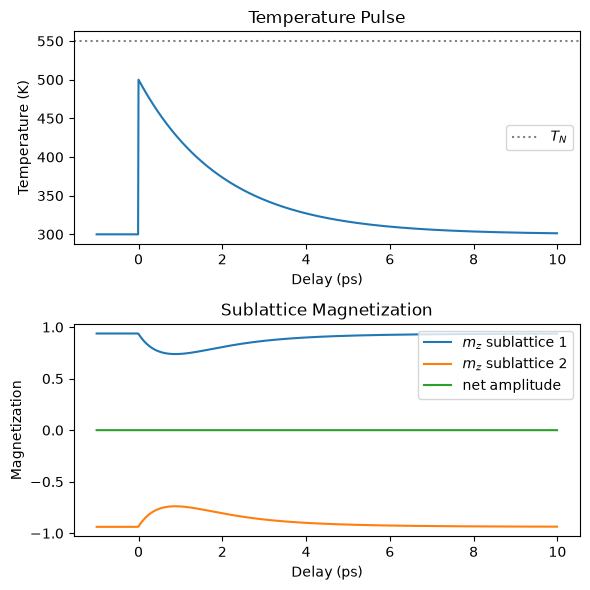

In [13]:
delays_AFM = np.r_[-1:10:0.01] * u.ps
t_AFM = delays_AFM.to("ps").magnitude
T_pulse = 300 + 200 * np.exp(-np.clip(t_AFM, 0, None) / 2) * (t_AFM >= 0)
temp_map_AFM = np.tile(T_pulse[:, np.newaxis], (1, 5))

sublattice_map = llb_AFM.get_sublattice_magnetization_map(delays_AFM, temp_map=temp_map_AFM)
net_map = llb_AFM.get_magnetization_map(delays_AFM, temp_map=temp_map_AFM)


plt.figure(figsize=[6, 6])
plt.subplot(2, 1, 1)
plt.plot(delays_AFM, T_pulse)
plt.axhline(layer_AFM.curie_temp.magnitude, color="gray", ls=":", label="$T_N$")
plt.xlabel("Delay (ps)")
plt.ylabel("Temperature (K)")
plt.legend()
plt.title("Temperature Pulse")
plt.subplot(2, 1, 2)
plt.plot(delays_AFM, sublattice_map[:, 0, 0, 2], label="$m_z$ sublattice 1")
plt.plot(delays_AFM, sublattice_map[:, 0, 1, 2], label="$m_z$ sublattice 2")
plt.plot(delays_AFM, np.linalg.norm(net_map[:, 0], axis=-1), label="net amplitude")
plt.xlabel("Delay (ps)")
plt.ylabel("Magnetization")
plt.legend()
plt.title("Sublattice Magnetization")
plt.tight_layout()
plt.show()

Both sublattices demagnetize and recover identically and stay antiparallel, so that the net magnetization vanishes at all times.
In a ferrimagnet with different sublattices, as in the [all-optical switching example](#example_eLLB), the sublattices evolve differently.